In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures, SplineTransformer
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.metrics import root_mean_squared_error

import os
os.chdir('/Users/lior/DS6021/DS6021_F26/data')
auto = pd.read_cs
v("Auto.csv", na_values="?").dropna().reset_index(drop=True)
print(auto.shape)
#claude was used to clean code in some sections

(392, 9)


cylinders
3      4
4    199
5      3
6     83
8    103
Name: count, dtype: int64


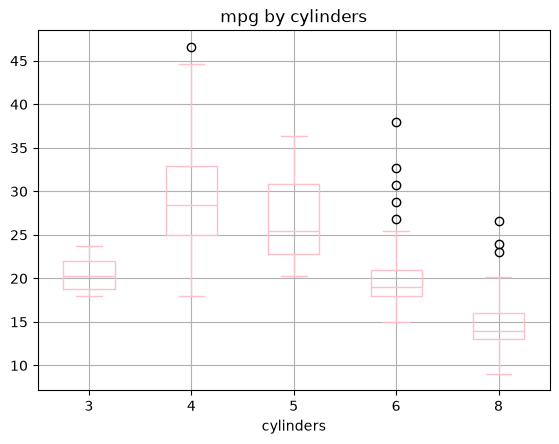

In [ ]:
#1a

print(auto["cylinders"].value_counts().sort_index())
auto.boxplot(column="mpg",by="cylinders", color="pink"); 
plt.suptitle(""); 
plt.title("mpg by cylinders"); 
plt.show()

In [ ]:
#1b
auto["cyl_rollup"]=np.where(auto["cylinders"] < 6, "<6",np.where(auto["cylinders"] == 6,"6", "8"))
print(auto["cyl_rollup"].value_counts())

cyl_rollup
<6    206
8     103
6      83
Name: count, dtype: int64


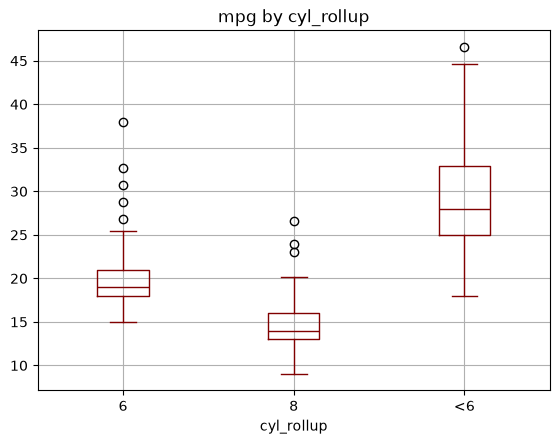

In [ ]:
#1c
auto.boxplot(column="mpg",by="cyl_rollup", color="maroon"); 
plt.suptitle(""); 
plt.title("mpg by cyl_rollup"); 
plt.show()

There were only 3 and 4 cars in the 3- and 5- cylinder groups which isnt enough to make a reliable assumption, but after replacing it with the rollup the groups are a lot more ballanced and there are fewer cylinders which means a higher mpg.

1d

Because its a text label thats unique for each car so theres no pattern associated with it and the model would just overfit it since it would memorize every car and not predict new cars.

In [8]:
#2a

num = ["displacement", "horsepower", "weight", "acceleration", "year"]
Xn, y = auto[num], auto["mpg"]
cv = KFold(n_splits=5, shuffle=True, random_state=42)
def sfs(direction, k):
    p = make_pipeline(StandardScaler(),
        SequentialFeatureSelector(LinearRegression(), n_features_to_select=k, direction=direction,cv=cv, scoring="neg_root_mean_squared_error"))
    p.fit(Xn, y)
    return list(p[:-1].get_feature_names_out()) if False else list(Xn.columns[p[-1].get_support()])
for k in [1, 2, 3, 4]:
    print(f"Forward k={k}:", sfs("forward",k))


Forward k=1: ['weight']
Forward k=2: ['weight', 'year']
Forward k=3: ['displacement', 'weight', 'year']
Forward k=4: ['displacement', 'horsepower', 'weight', 'year']


weight -> year -> displacement -> horsepower

In [9]:
print("Backward k=3:", sfs("backward", 3))

Backward k=3: ['displacement', 'weight', 'year']


Yes, they pick the same three features but it doesnt guarantee that they found the best model since they both are checking one step at a time and never looking back, so they wouldnt have a way of double checking if it was the best one or not.

In [10]:
#2c

print(auto[["displacement", "horsepower", "weight"]].corr().round(3))
Xv = sm.add_constant(auto[["displacement", "horsepower", "weight"]])
print(pd.Series([variance_inflation_factor(Xv.values, i) for i in range(1, 4)],index=["displacement", "horsepower", "weight"]).round(2))

              displacement  horsepower  weight
displacement         1.000       0.897   0.933
horsepower           0.897       1.000   0.865
weight               0.933       0.865   1.000
displacement    10.31
horsepower       5.29
weight           7.96
dtype: float64


weight, horsepower, and displacement are highly correlated from 0.87 to 0.93, and displacement & weight have have high VIFs (10.31 and 7.96 respectively). for forward, when one of the features is added the others dont add a ton of new information so theyre just skipped and which one gets in first just depends on the differences in the data. With backwards, it starts with all of the features so all of them share credit and each look less useful, so removing one makes the other feature look more useful.